In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [2]:
import zipfile
import os

zip_file = list(uploaded.keys())[0]

extract_path = "/content/cat_dog_dataset"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [3]:
for root, dirs, files_list in os.walk(extract_path):
    print(root, dirs)

/content/cat_dog_dataset ['dogs_set', 'cats_set']
/content/cat_dog_dataset/dogs_set []
/content/cat_dog_dataset/cats_set []


In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, models
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

In [7]:
# Use the extracted path directly since there are no pre-split folders
train_ds = tf.keras.utils.image_dataset_from_directory(
    extract_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    extract_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names
print("Classes:", class_names)

Found 1000 files belonging to 2 classes.
Using 800 files for training.
Found 1000 files belonging to 2 classes.
Using 200 files for validation.
Classes: ['cats_set', 'dogs_set']


In [9]:
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

Create a common model training function

In [17]:
results = {}

def train_and_evaluate(model, model_name, train_data, val_data, test_data):

    print("\nTraining", model_name)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=2,
            min_lr=0.000001
        )
    ]

    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=20,
        callbacks=callbacks
    )

    # Test evaluation
    test_loss, test_accuracy = model.evaluate(test_data)

    print("\n", model_name, "Test Accuracy:",
          round(test_accuracy * 100, 2), "%")

    # Predictions
    y_true = np.concatenate([
        y.numpy().ravel() for x, y in test_data
    ])

    y_prob = model.predict(test_data).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    # Accuracy graph
    plt.figure(figsize=(7, 5))
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(model_name + " Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid()
    plt.show()

    # Loss graph
    plt.figure(figsize=(7, 5))
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(model_name + " Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid()
    plt.show()

    # Explicit targets
    targets = ['cats', 'dogs']

    # Confusion matrix with explicit labels to avoid shape mismatches
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=targets,
        yticklabels=targets
    )
    plt.title(model_name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    # Classification report with explicit labels
    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=targets,
        zero_division=0
    ))

    results[model_name] = {
        "accuracy": test_accuracy * 100,
        "loss": test_loss,
        "model": model,
        "history": history
    }

    return model

MODEL 1: MobileNetV2

In [11]:
base_mobilenet = tf.keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_mobilenet.trainable = False

mobilenet_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),

    layers.Lambda(
        tf.keras.applications.mobilenet_v2.preprocess_input
    ),

    base_mobilenet,

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation='relu'),

    layers.Dropout(0.3),

    layers.Dense(1, activation='sigmoid')
])

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step



Training MobileNetV2
Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 16s 208ms/step - accuracy: 0.8000 - loss: 0.4499 - val_accuracy: 0.9900 - val_loss: 0.1470 - learning_rate: 1.0000e-04
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - accuracy: 0.9563 - loss: 0.1797 - val_accuracy: 0.9900 - val_loss: 0.0924 - learning_rate: 1.0000e-04
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - accuracy: 0.9650 - loss: 0.1212 - val_accuracy: 0.9900 - val_loss: 0.1001 - learning_rate: 1.0000e-04
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - accuracy: 0.9663 - loss: 0.1077 - val_accuracy: 0.9900 - val_loss: 0.0520 - learning_rate: 1.0000e-04
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accuracy: 0.9725 - loss: 0.0905 - val_accuracy: 0.9900 - val_loss: 0.0538 - learning_rate: 1.0000e-04
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accuracy: 0.9862 - loss: 0.0630 - val_accuracy: 0.9900 - val_loss: 0.0589 - learning_rate: 1.0000e-04
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 100ms

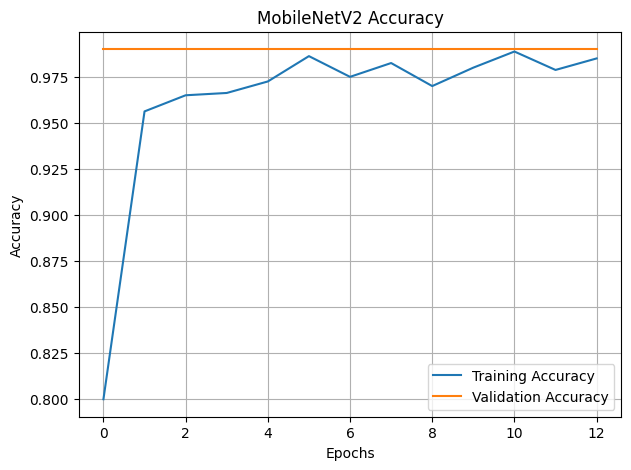

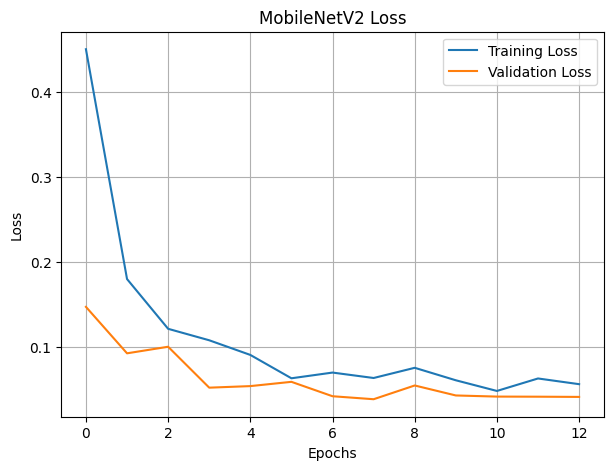

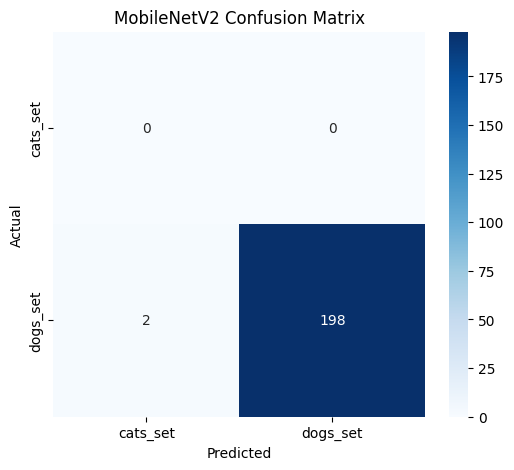


Classification Report:
              precision    recall  f1-score   support

    cats_set       0.00      0.00      0.00         0
    dogs_set       1.00      0.99      0.99       200

    accuracy                           0.99       200
   macro avg       0.50      0.49      0.50       200
weighted avg       1.00      0.99      0.99       200



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [13]:
mobilenet_model = train_and_evaluate(
    mobilenet_model,
    "MobileNetV2",
    train_ds,
    val_ds,
    val_ds
)

MODEL 2: EfficientNetB0

In [14]:
base_efficientnet = tf.keras.applications.EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_efficientnet.trainable = False

efficientnet_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),

    base_efficientnet,

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation='relu'),

    layers.Dropout(0.3),

    layers.Dense(1, activation='sigmoid')
])

efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step



Training EfficientNetB0
Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 113ms/step - accuracy: 0.9962 - loss: 0.0232 - val_accuracy: 0.9950 - val_loss: 0.0179 - learning_rate: 1.2500e-05
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - accuracy: 0.9937 - loss: 0.0260 - val_accuracy: 0.9950 - val_loss: 0.0179 - learning_rate: 1.2500e-05
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 123ms/step - accuracy: 0.9962 - loss: 0.0261 - val_accuracy: 0.9950 - val_loss: 0.0177 - learning_rate: 1.2500e-05
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - accuracy: 0.9925 - loss: 0.0252 - val_accuracy: 0.9950 - val_loss: 0.0176 - learning_rate: 1.2500e-05
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - accuracy: 0.9937 - loss: 0.0235 - val_accuracy: 0.9950 - val_loss: 0.0174 - learning_rate: 1.2500e-05
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 115ms/step - accuracy: 0.9950 - loss: 0.0209 - val_accuracy: 0.9950 - val_loss: 0.0172 - learning_rate: 1.2500e-05
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 3

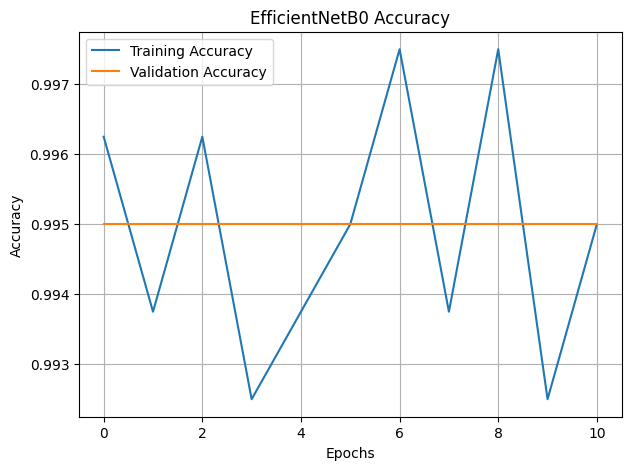

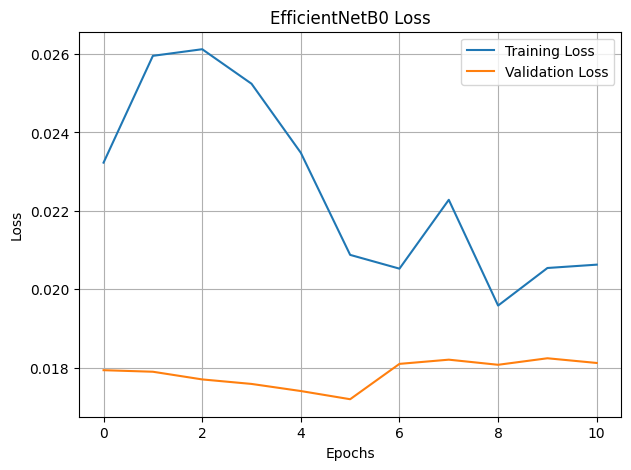

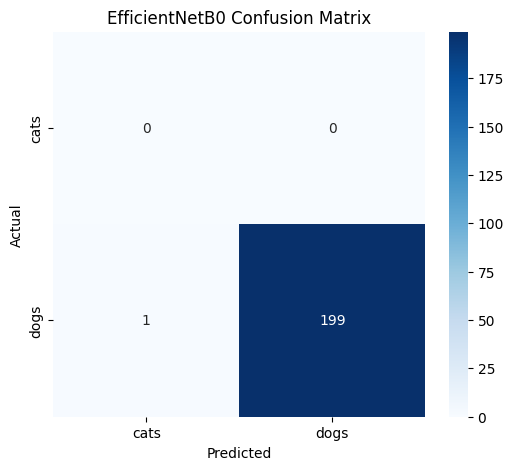


Classification Report:
              precision    recall  f1-score   support

        cats       0.00      0.00      0.00         0
        dogs       1.00      0.99      1.00       200

    accuracy                           0.99       200
   macro avg       0.50      0.50      0.50       200
weighted avg       1.00      0.99      1.00       200



In [23]:
efficientnet_model = train_and_evaluate(
    efficientnet_model,
    "EfficientNetB0",
    train_ds,
    val_ds,
    val_ds
)

MODEL 3: ResNet50




In [20]:
base_resnet = tf.keras.applications.ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_resnet.trainable = False

resnet_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),

    layers.Lambda(
        tf.keras.applications.resnet50.preprocess_input
    ),

    base_resnet,

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation='relu'),

    layers.Dropout(0.3),

    layers.Dense(1, activation='sigmoid')
])

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step



Training ResNet50
Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 19s 363ms/step - accuracy: 0.7900 - loss: 0.4426 - val_accuracy: 0.9350 - val_loss: 0.1850 - learning_rate: 1.0000e-04
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 200ms/step - accuracy: 0.9675 - loss: 0.1295 - val_accuracy: 0.9950 - val_loss: 0.0463 - learning_rate: 1.0000e-04
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 201ms/step - accuracy: 0.9762 - loss: 0.0920 - val_accuracy: 0.9900 - val_loss: 0.0486 - learning_rate: 1.0000e-04
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 207ms/step - accuracy: 0.9837 - loss: 0.0670 - val_accuracy: 0.9900 - val_loss: 0.0369 - learning_rate: 1.0000e-04
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 199ms/step - accuracy: 0.9825 - loss: 0.0550 - val_accuracy: 0.9950 - val_loss: 0.0264 - learning_rate: 1.0000e-04
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 201ms/step - accuracy: 0.9850 - loss: 0.0581 - val_accuracy: 0.9950 - val_loss: 0.0203 - learning_rate: 1.0000e-04
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 185

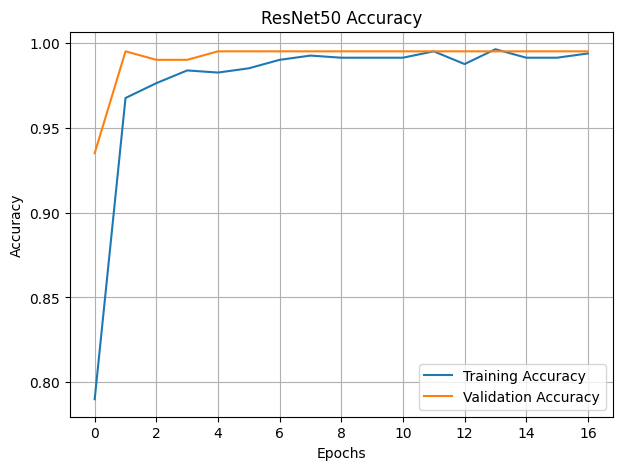

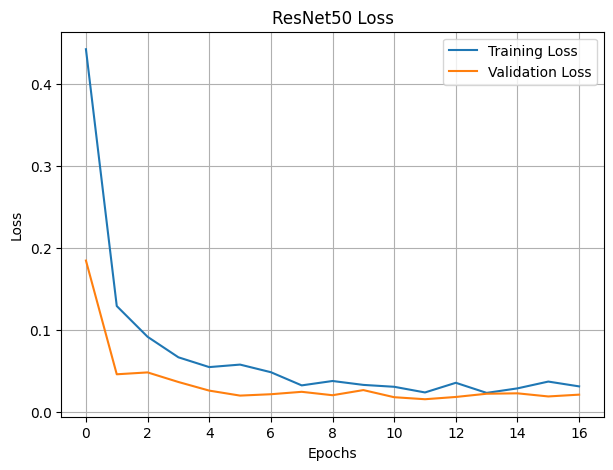

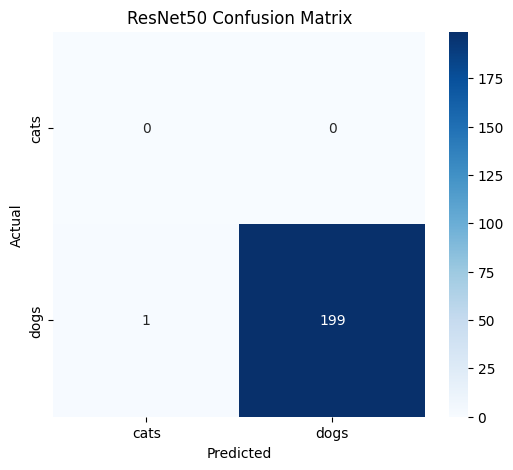


Classification Report:
              precision    recall  f1-score   support

        cats       0.00      0.00      0.00         0
        dogs       1.00      0.99      1.00       200

    accuracy                           0.99       200
   macro avg       0.50      0.50      0.50       200
weighted avg       1.00      0.99      1.00       200



In [25]:
resnet_model = train_and_evaluate(
    resnet_model,
    "ResNet50",
    train_ds,
    val_ds,
    val_ds
)

Compare all three models

In [26]:
print("\nFINAL MODEL ACCURACY COMPARISON")

for name, data in results.items():
    print(name, ":", round(data["accuracy"], 2), "%")


FINAL MODEL ACCURACY COMPARISON
MobileNetV2 : 99.0 %
EfficientNetB0 : 99.5 %
ResNet50 : 99.5 %


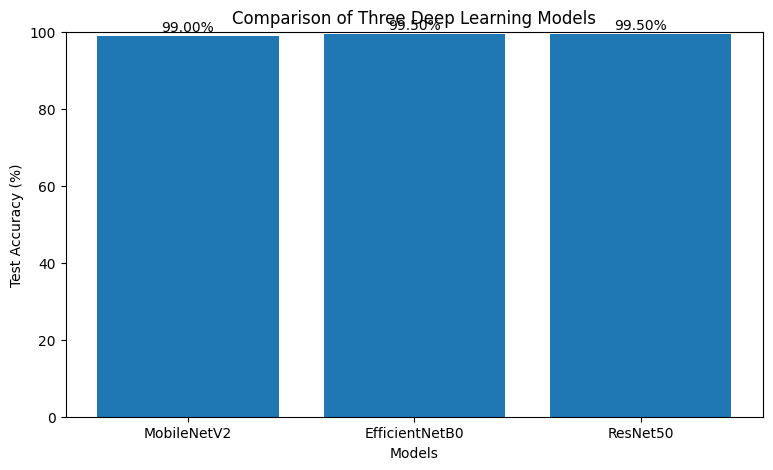

In [27]:
model_names = list(results.keys())

accuracies = [
    results[name]["accuracy"]
    for name in model_names
]

plt.figure(figsize=(9, 5))

plt.bar(model_names, accuracies)

plt.title("Comparison of Three Deep Learning Models")
plt.xlabel("Models")
plt.ylabel("Test Accuracy (%)")

plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f"{value:.2f}%", ha='center')

plt.show()